# Feasible plan and certified bound: CPIT methods

**Question:** How does the CPIT schedule gap to its certified bound change across methods?

**Level**: 2

**Prerequisites**: 01-problem-and-published-data

**Reading time**: 28 minutes

## Objectives

A feasible integer schedule and a certified relaxation bound the unknown optimum from opposite sides. This lesson separates that distance from differences among heuristics and runs all methods on the same instance. By the end, you can distinguish certificate distance from heuristic quality, interpret resource load, and explain why none of these outputs proves global optimality.

## Setup

From the repository root, install the pinned environment with these versions. The cell reports the versions actually imported.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the API and verify versions.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

PhaseFlow maintains the deterministic generator and instance builder; its code is MIT-licensed. The case declares a vein, seed 31, dimensions 4×4×3, four periods, and capacities; it is not field data. twin-porphyry-s is a separate derived manifest. Newman1 is a MineLib aggregate; its block files have academic-download terms and are not redistributed.

Per-file provenance: the committed aggregates are data/derived/manifests/newman1-published.json and data/derived/manifests/twin-porphyry-s.json. MineLib publishes its record at https://minelib.org/v1/Results.xhtml; MineLib owns the benchmark, and its source files carry academic-download terms. PhaseFlow owns the synthetic generator at https://github.com/fsantibanezleal/CAOS_PhaseFlow under the MIT license; its implementation is data-pipeline/pipeline/model/instances.py. The seed and scenario for this example are explicit in code.

In [2]:
# Build the instance through the pipeline and read committed aggregates.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contract accepted:',instance.report.ok,'| blocks:',instance.n_blocks)
print('committed cases:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contract accepted: True | blocks: 48
committed cases: newman1-published twin-porphyry-s


## Method

For maximization, Z_plan <= Z_star <= Z_LP. For one resource with capacity U, the parametric relaxation is CP(U) = min over lambda >= 0 of [UPL(p - lambda*a) + lambda*U]. Chicoisne et al. (2012), https://doi.org/10.1287/opre.1120.1050, ground the maximum closures and certificate.

A feasible schedule is a lower bound on the unknown integer optimum; a relaxation is an upper bound. For maximization, Z_plan <= Z_star <= Z_LP. The displayed percentage 100 (Z_bound - Z_plan)/Z_bound is distance to the available certificate. It is not the schedule's true suboptimality unless the upper bound equals the integer optimum, which is usually unknown. This distinction must survive every comparison.

For a single resource with capacity U and block usage a, the parametric closure value is CP(U) = min over lambda >= 0 of [UPL(p - lambda*a) + lambda*U]. The multiplier prices resource use; maximum closures change at breakpoints. OreBlocks computes the critical-multiplier bound. We inspect the result for each resource, including closure counts, before taking the minimum Algorithm 4 bound.

Each single-resource relaxation removes other capacity rows. Its feasible set contains the original one, so its optimum is a valid upper bound. The minimum across resources remains valid but can be weaker than the joint LP: mining and processing may bind in different periods. This notebook does not label the Algorithm 4 certificate as a joint Bienstock-Zuckerberg bound or an exact integer optimum.

To isolate method effects, every candidate uses the same instance, capacities, discounting and reference bound. Greedy, Gershon and Expected alter the package's eligible-block ordering; sliding window adds bounded mixed-integer reoptimization on a moving horizon. These are OreBlocks methods, not notebook implementations. The explicit time limit is part of the result: extra search time can change a candidate.

The resource plot displays tonnes assigned to each period and constant capacity lines. It can identify a period close to a limit; it does not show precedence or discounted economics. A chart is a diagnostic, not a validator. OreBlocks controls inspect the full arrays and test independent invariants. If the chart and controls appear inconsistent, investigate resource indexing and returned result fields instead of choosing the more reassuring view.

The method-gap figure uses a single upper-bound denominator. A lower bar means higher feasible NPV on this instance. It does not rank algorithms universally, demonstrate a scaling law, or prove optimality. Sliding window has a neighborhood, solver and time budget that affect its result. The set is deliberately small for inspection and cannot stand in for PhaseFlow's published case evaluation.

Finally, local improvement receives the Expected candidate and returns an accepted schedule. We compare its value before and after, then run the package controls again on the returned value. A non-decrease is expected; equality means no better move was accepted within the configured passes, not that no better plan exists. The remaining gap to the relaxation is still uncertainty.

Research results belong to their cited instances, formulations, software and machines. Newman1's aggregate and the twin-porphyry manifest are contextual evidence, not the inputs to this seeded 48-block run. A claim about a baked case must use that case's own manifest, trace and dossier. This controlled lesson explains mechanisms; it does not reproduce a published table or support a product-wide ranking.

Step 1. Compute each resource relaxation and retain the smaller Algorithm 4 bound.

In [3]:
# Compute the package critical-multiplier relaxation for each resource.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
for item in relaxations:
    print(item.resource,round(item.bound,2),item.closure_solves)
bound=min(item.bound for item in relaxations)
print('shared valid upper bound:',round(bound,2))

0 333680.0 31
1 284685.82 57
shared valid upper bound: 284685.82


The computed table orders four methods using one shared, valid Algorithm 4 certificate. It reports NPV, mined blocks, gap, and an independent bound-direction check for each candidate. Read it as a controlled comparison on this seed; it does not rank methods across deposits.


In [4]:
# Run package scheduling methods with identical inputs.
greedy=ob.toposort_schedule(instance.cpit,instance.precedence,weight='greedy',relaxation=relaxations[0])
gershon=ob.toposort_schedule(instance.cpit,instance.precedence,weight='gershon',relaxation=relaxations[0])
expected=ob.toposort_schedule(instance.cpit,instance.precedence,weight='expected',relaxation=relaxations[0])
window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence,
    window=2, fix=1, node_limit=50, mip_gap=0.01,
    relaxation=relaxations[0],
)
methods={'Greedy':greedy,'Gershon':gershon,'Expected':expected,'Sliding window':window}

This table reports NPV, mined blocks, and gap to one shared upper bound. Result-specific bounds are kept separate because the comparison uses the minimum across resources. Differences are observed on this instance; they do not imply a universal advantage.

In [5]:
# Compare package methods against one certificate and validate every schedule.
from IPython.display import HTML, display
rows = [
    {'method': name, 'NPV': item.npv, 'mined blocks': item.mined_blocks,
     'gap %': 100 * (bound - item.npv) / bound,
     'bound valid': ob.run_controls(instance.cpit, instance.precedence, item).bound_geq_feasible}
    for name, item in methods.items()
]
comparison = sorted(rows, key=lambda row: row['NPV'], reverse=True)
header = '<tr><th>Method</th><th>NPV</th><th>Mined blocks</th><th>Gap (%)</th><th>Bound valid</th></tr>'
body_rows = []
for row in comparison:
    cells = ''.join('<td>' + str(value) + '</td>' for value in row.values())
    body_rows.append('<tr>' + cells + '</tr>')
body = ''.join(body_rows)
display(HTML('<table>' + header + body + '</table>'))

Method,NPV,Mined blocks,Gap (%),Bound valid
Sliding window,237344.6739517331,4,16.629261634553774,True
Greedy,179593.13651741008,16,36.91532172376548,True
Expected,179078.25303085113,16,37.0961819711512,True
Gershon,-74237.99018199826,16,126.07716429102854,True


The table ranks four measured NPVs: Sliding window reaches 237344.67 and the smallest gap, 16.629%; Gershon is negative on this instance. The control column confirms every feasible value remains below the shared certificate. This outcome depends on the seed and 50-node budget; it does not establish universal method quality or a global optimum.

Step 3. Use Expected and compare tonnes per period with both limits.

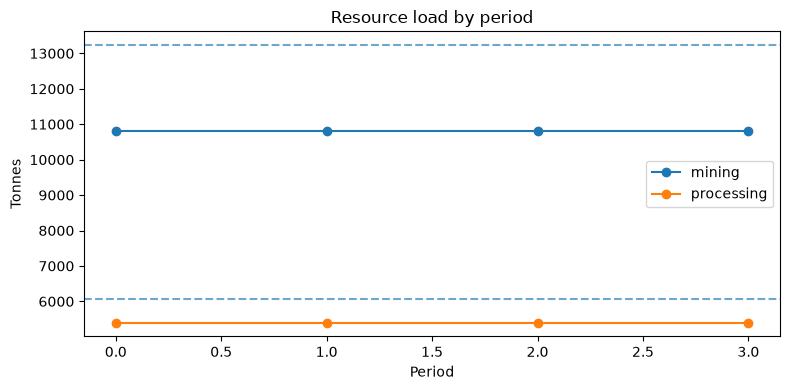

In [6]:
# Plot full resource use by period against constant limits.
fig,ax=plt.subplots(figsize=(8,4))
for r,label in enumerate(('mining','processing')):
    ax.plot(range(instance.cpit.n_periods),expected.per_period_resource[r],marker='o',label=label)
    ax.axhline(instance.cpit.limit[r,0],linestyle='--',alpha=.65)
ax.set(
    title='Resource load by period', xlabel='Period', ylabel='Tonnes',
)
ax.legend()
fig.tight_layout()
plt.show()

The two curves and dashed lines show tonnes used and capacity by resource. Identify the period with highest utilization; do not infer precedence or discounted value from this plot. Package controls check the full matrix and remain the feasibility authority.

Step 4. Plot computed gaps against the same upper bound.

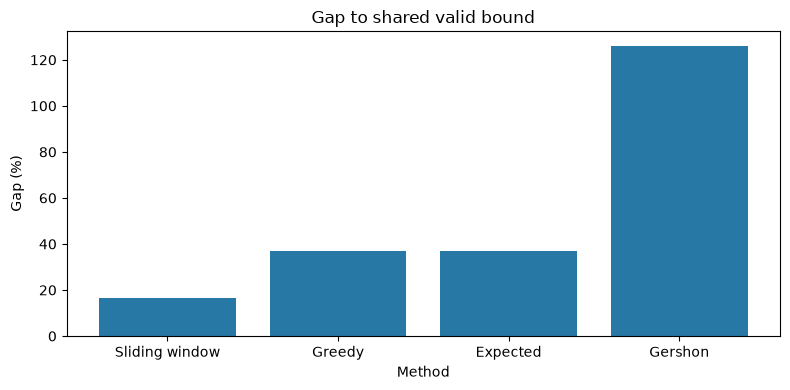

In [7]:
# Plot comparable gaps so a shorter bar means a stronger feasible value here.
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([row['method'] for row in comparison], [row['gap %'] for row in comparison], color='#2878a5')
ax.set(title='Gap to shared valid bound',xlabel='Method',ylabel='Gap (%)')
fig.tight_layout()
plt.show()

This figure orders measured distances for this run; a shorter bar means the schedule sits closer to the shared certificate, not that it is universally better. Sliding window used a deterministic node limit that bounds its search. Neither the gap nor solver termination proves global optimality.

In [8]:
# Improve Expected locally, then re-run independent package controls.
improved=ob.improve_schedule(instance.cpit,instance.precedence,expected)
controls=ob.run_controls(instance.cpit,instance.precedence,improved)
print('improved NPV:',round(improved.npv,2),'from:',round(expected.npv,2))
print(controls.__dict__)
best=comparison[0]
print('best method:',best['method'],'NPV:',round(best['NPV'],2),'gap %:',round(best['gap %'],3))

improved NPV: 179078.25 from: 179078.25
{'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}
best method: Sliding window NPV: 237344.67 gap %: 16.629


The local improvement changes a feasible incumbent, so rerun the independent bound and order checks before interpreting its value.

In [9]:
# Recheck the improved incumbent with the independent control suite.
improved_controls = ob.run_controls(instance.cpit, instance.precedence, improved)
print('improved controls pass:', improved_controls.all_pass)


improved controls pass: True


## Results

**Answer:** Sliding window returned the highest measured NPV, 237344.67, with a 16.629% gap to the shared 284685.82 bound. The figures show resource use and gaps on this instance. The node limit is part of the method; global optimality is not established.

## Summary

The relaxation certifies a ceiling; scheduling methods produce feasible plans and local improvement may close part of the gap. The residual combines relaxation slack and heuristic loss. This small experiment teaches the mechanism; baked-case dossiers and traces hold the evidence for product comparisons.

## References

- Chicoisne et al. (2012), parametric maximum closures: https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020), evaluated scheduling methods: https://doi.org/10.1287/opre.2019.1965
- MineLib Newman1 aggregate record: https://minelib.org/v1/Results.xhtml
- PhaseFlow method dossier: docs/methodologies/02_the-bound.md
- PhaseFlow case dossier: docs/cases/04_twin-porphyry-s.md
- PhaseFlow source repository and synthetic-twin generator: https://github.com/fsantibanezleal/CAOS_PhaseFlow